# 03. 사전 분석 (1) 월별 KPI로 문제 위치 좁히기

- 분석 시점: 2026-08-17 (7월 실적 마감 직후, 분석 요청 접수)
- 요청: 하반기 온라인 매출 목표(+25%) 대비 7월 실적 +12%로 미달. 신규 고객 매출 달성률이 특히 낮음 → 원인 파악 (`docs/02_business_brief.md`)
- 이 노트북의 범위: **경영 리포트 월별 KPI(`raw.kpi_monthly`)로 "어디가 문제인지"를 좁힘**
  - "왜, 어디서 이탈하는지"는 다음 단계에서 이벤트 로그로 확인
- 진행 방식: 질문 → 방법 후보 → 선택 이유 → 결과 → 해석 → 다음 질문
- SQL은 `sql/analysis/` 파일에 두고 이 노트북에서 읽어 실행함 (같은 쿼리를 노트북마다 복사하지 않기 위해)

## 0. 설정

In [1]:
import sys
sys.path.append("..")                                   # 상위 폴더의 config.py를 불러오기 위해 경로 추가
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.cloud import bigquery
import pydata_google_auth
from config import PROJECT_ID, LOCATION, MAX_BYTES_BILLED

# BigQuery 연결 (연결 테스트 노트북과 같은 방식)
credentials = pydata_google_auth.get_user_credentials(["https://www.googleapis.com/auth/bigquery"])
client = bigquery.Client(project=PROJECT_ID, credentials=credentials, location=LOCATION,
                         default_query_job_config=bigquery.QueryJobConfig(maximum_bytes_billed=MAX_BYTES_BILLED))

SQL_DIR = "../sql/analysis"

def run_sql(file_name):
    """sql/analysis/ 폴더의 SQL 파일을 읽어 BigQuery에서 실행하고 DataFrame으로 돌려줌"""
    with open(f"{SQL_DIR}/{file_name}", encoding="utf-8") as f:
        sql = f.read()
    return client.query(sql).to_dataframe(create_bqstorage_client=False)   # Storage API는 쓰지 않음 (결과가 작아서 충분)

def query(sql):
    """짧은 SQL 문자열을 바로 실행"""
    return client.query(sql).to_dataframe(create_bqstorage_client=False)

# 그래프 한글 폰트 (Mac 기본 한글 폰트), 마이너스 기호 깨짐 방지
plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.float_format", "{:,.2f}".format)   # 소수점 둘째 자리, 천 단위 쉼표

## 1. 미달은 어디서 났나

**질문**
- 1~7월 누적 실적에서 기존 고객과 신규 고객 중 어느 쪽이 목표에 못 미쳤나

**방법 후보**

| 방법 | 판단 |
|---|---|
| 고객 유형별 성장률을 그대로 비교·합산 | 기각. 기존 고객이 매출의 약 85%라서 유형별 성장률을 더해도 전체 성장률이 되지 않음 (비중이 빠짐) |
| 월별 성장률만 비교 | 월마다 흔들림이 커서 경향을 보기 어려움 → 참고용 |
| **누적(1월~해당 월) 성장률을 기여도(%p)로 분해** | 채택. 기여도 = 유형별 성장률 × 전년 매출 비중 → 두 기여도의 합이 전체 성장률과 정확히 같아짐 |

**비교 기준: 요청서의 목표 구성을 기여도로 환산**
- 요청서 기준 연간 목표 +18%, 기존 고객은 추세 성장(+13%)을 전제
- 실적과 같은 기준(기여도 %p)으로 비교하기 위해, 2025년 실제 매출 비중으로 목표를 기존·신규 몫으로 나눠둠

In [2]:
# 월별 KPI 전체 (19행이라 전체를 가져와도 처리량이 매우 작음)
# 아래 계산은 분석 질문이 아니라 실적과 비교할 기준(목표의 기존·신규 몫)을 만드는 단계
kpi = query("SELECT * FROM raw.kpi_monthly ORDER BY month")
kpi["month"] = pd.to_datetime(kpi["month"])

# 2025년 연간 매출 중 신규 고객 비중
y2025 = kpi[kpi["month"].dt.year == 2025]
new_share = y2025["revenue_new"].sum() / (y2025["revenue_new"].sum() + y2025["revenue_existing"].sum())

# 목표 구성: 기존 고객은 추세(+13%)대로 성장한다고 보고, 나머지를 신규가 채워야 하는 구조
TARGET = 0.18                                  # 연간 목표 성장률
EXISTING_TREND = 0.13                          # 기존 고객 추세 성장률 (전년 성장률 기준)
existing_contrib = EXISTING_TREND * (1 - new_share)          # 기존 고객 기여 (%p)
new_contrib = TARGET - existing_contrib                      # 신규 고객이 채워야 하는 기여 (%p)
new_growth_needed = new_contrib / new_share                  # 그만큼 기여하려면 신규 매출이 성장해야 하는 비율

plan = pd.DataFrame({
    "전년 매출 비중(%)": [(1 - new_share) * 100, new_share * 100],
    "필요 성장률(%)": [EXISTING_TREND * 100, new_growth_needed * 100],
    "목표 기여(%p)": [existing_contrib * 100, new_contrib * 100],
}, index=["기존 고객", "신규 고객"])
plan

,전년 매출 비중(%),필요 성장률(%),목표 기여(%p)
기존 고객,85.48,13.00,11.11
신규 고객,14.52,47.43,6.89


- 목표 구성 (기여도 기준): 기존 고객 약 +11.1%p, 신규 고객 약 +6.9%p
- 신규 몫을 채우려면 신규 매출이 약 +47% 성장해야 하는 목표 → 이 기준과 실적을 아래에서 비교

- 성장률: `sql/analysis/01_kpi_yoy.sql` (월별·누적 성장률, 윈도우 함수 `SUM() OVER`, `LAG`)
- 기여도: `sql/analysis/02_kpi_contribution.sql`

In [3]:
# 고객 유형별 월별·누적 성장률 (전년 동월 대비)
yoy = run_sql("01_kpi_yoy.sql").sort_values("month").reset_index(drop=True)
yoy

,month,신규 매출 2025,신규 매출 2026,신규 매출 Uplift,신규 누적 매출 2025,신규 누적 매출 2026,신규 누적 매출 Uplift,기존 매출 2025,기존 매출 2026,기존 매출 Uplift,기존 누적 매출 2025,기존 누적 매출 2026,기존 누적 매출 Uplift
0,2026-01-01,3195768936,2791998988,-12.63,3195768936,2791998988,-12.63,18602298890,21032544309,13.06,18602298890,21032544309,13.06
1,2026-02-01,2945863965,2633075324,-10.62,6141632901,5425074312,-11.67,18021623503,20385082931,13.11,36623922393,41417627240,13.09
2,2026-03-01,3196442032,2931605116,-8.29,9338074933,8356679428,-10.51,19469292721,21754504176,11.74,56093215114,63172131416,12.62
3,2026-04-01,3244459736,2663872750,-17.89,12582534669,11020552178,-12.41,18906992686,21741153077,14.99,75000207800,84913284493,13.22
4,2026-05-01,3329377374,2992360851,-10.12,15911912043,14012913029,-11.93,19349184054,22647633694,17.05,94349391854,107560918187,14.00
5,2026-06-01,3421964987,3111893307,-9.06,19333877030,17124806336,-11.43,19641010968,22240708589,13.24,113990402822,129801626776,13.87
6,2026-07-01,3279878000,3354179250,2.27,22613755030,20478985586,-9.44,19150000000,21800000000,13.84,133140402822,151601626776,13.87


In [4]:
# 누적 성장률을 기존 / 신규 기여도(%p)로 나눔
contrib = run_sql("02_kpi_contribution.sql")

# 검산: 두 기여도의 합이 전체 성장률과 같아야 함 (반올림 오차 0.01 이내)
assert (contrib["existing_contrib_pp"] + contrib["new_contrib_pp"] - contrib["total_growth_pct"]).abs().max() <= 0.02
contrib

,month,total_growth_pct,existing_contrib_pp,new_contrib_pp,new_share_ly_pct
0,2026-01-01,9.30,11.15,-1.85,14.70
1,2026-02-01,9.53,11.21,-1.68,14.40
2,2026-03-01,9.32,10.82,-1.50,14.30
3,2026-04-01,9.54,11.32,-1.78,14.40
4,2026-05-01,10.26,11.98,-1.72,14.40
5,2026-06-01,10.20,11.86,-1.66,14.50
6,2026-07-01,10.48,11.85,-1.37,14.50


In [5]:
# 7월 누적 기준으로 목표 구성(위 비교 기준)과 비교
jul = contrib.iloc[-1]
compare = pd.DataFrame({
    "목표(%p)": [existing_contrib * 100, new_contrib * 100, TARGET * 100],
    "실적(%p)": [jul["existing_contrib_pp"], jul["new_contrib_pp"], jul["total_growth_pct"]],
}, index=["기존 고객 기여", "신규 고객 기여", "전체 성장률"])
compare["차이(%p)"] = compare["실적(%p)"] - compare["목표(%p)"]
compare

,목표(%p),실적(%p),차이(%p)
기존 고객 기여,11.11,11.85,0.74
신규 고객 기여,6.89,-1.37,-8.26
전체 성장률,18.00,10.48,-7.52


**해석 (1~7월 누적)**
- 기존 고객 기여 약 +11.9%p → 목표(+11.1%p)을 오히려 조금 넘음. 기존 고객 매출은 매달 +12~17%로 추세대로 감
- 신규 고객 기여 약 **-1.4%p** → 목표(+6.9%p) 대비 약 -8%p. 신규 매출은 오히려 전년보다 줄어듦 (누적 약 -9%)
- 전체 성장률 약 +10.5%로 목표(+18%) 대비 -7.5%p
- **목표 미달분 전부가 신규 고객에서 나옴.** 기존 고객은 문제가 아님

**다음 질문** → 신규 매출이 왜 줄었나? 방문이 줄었나, 전환이 안 됐나, 덜 샀나?

## 2. 신규 매출의 어느 요소가 문제인가

**질문**
- 신규 매출 = 신규 방문 고객 수 × 첫 구매 전환율 × 첫 주문 평균 금액. 세 요소 중 무엇이 신규 매출을 끌어내렸나

**방법 후보**

| 방법 | 판단 |
|---|---|
| 요소별 전년 대비 성장률을 나란히 비교 | 방향은 보이지만, 곱셈 관계라 성장률을 더해도 매출 성장률과 맞지 않음 → 어느 요소가 얼마나 기여했는지 말할 수 없음 |
| **로그 분해** | 채택. `LN(매출 배수) = LN(방문 배수) + LN(전환율 배수) + LN(금액 배수)`로 곱셈이 덧셈이 되어 합이 정확히 맞음. 로그 값 ×100은 대략 %로 읽으면 됨 |

- `sql/analysis/03_new_revenue_decomposition.sql`
- 전환율은 반올림된 `new_first_purchase_rate` 대신 `new_buyers ÷ new_visitors`로 다시 계산 (반올림 오차로 곱셈 관계가 어긋나지 않도록)

In [6]:
decomp = run_sql("03_new_revenue_decomposition.sql")

# 검산: 세 요소 로그 값의 합 = 신규 매출 로그 값
decomp["ln_합계"] = decomp["ln_visitors"] + decomp["ln_conv_rate"] + decomp["ln_aov"]
assert (decomp["ln_합계"] - decomp["ln_revenue_new"]).abs().max() < 0.001
decomp

,month,visitors_yoy_pct,conv_rate_yoy_pct,aov_yoy_pct,revenue_new_yoy_pct,ln_visitors,ln_conv_rate,ln_aov,ln_revenue_new,ln_합계
0,2026-01-01,6.50,-21.92,5.07,-12.63,0.06,-0.25,0.05,-0.14,-0.14
1,2026-02-01,4.11,-18.92,5.89,-10.62,0.04,-0.21,0.06,-0.11,-0.11
2,2026-03-01,10.91,-22.54,6.75,-8.29,0.10,-0.26,0.07,-0.09,-0.09
3,2026-04-01,5.01,-23.82,2.64,-17.89,0.05,-0.27,0.03,-0.20,-0.20
4,2026-05-01,2.16,-16.00,4.74,-10.12,0.02,-0.17,0.05,-0.11,-0.11
5,2026-06-01,7.69,-19.87,5.39,-9.06,0.07,-0.22,0.05,-0.10,-0.10
6,2026-07-01,35.71,-27.65,4.15,2.27,0.31,-0.32,0.04,0.02,0.02


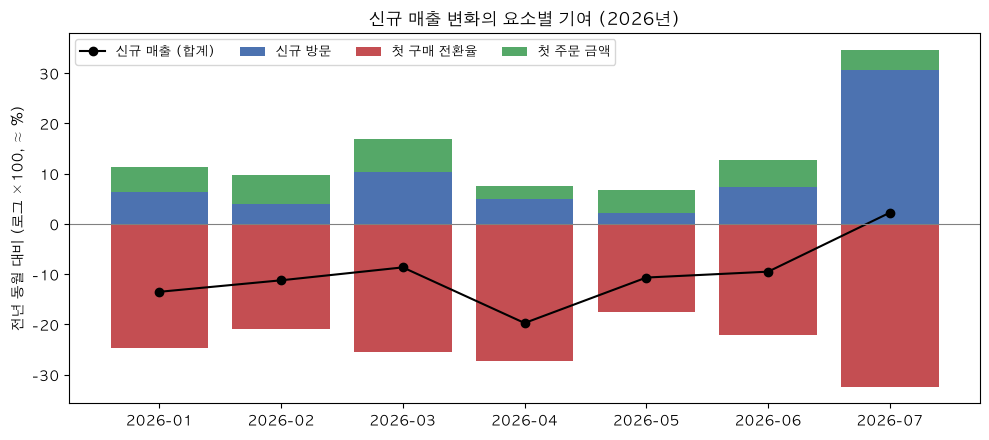

In [7]:
# 월별 로그 분해를 누적 막대로 표시: 막대 위쪽은 신규 매출을 올린 요소, 아래쪽은 끌어내린 요소
labels = decomp["month"].astype(str).str[:7]
parts = {"신규 방문": decomp["ln_visitors"], "첫 구매 전환율": decomp["ln_conv_rate"], "첫 주문 금액": decomp["ln_aov"]}
colors = {"신규 방문": "#4C72B0", "첫 구매 전환율": "#C44E52", "첫 주문 금액": "#55A868"}

fig, ax = plt.subplots(figsize=(10, 4.5))
pos_bottom = np.zeros(len(decomp)); neg_bottom = np.zeros(len(decomp))
for name, vals in parts.items():
    vals = vals.to_numpy()
    bottom = np.where(vals >= 0, pos_bottom, neg_bottom)           # 양수는 위로, 음수는 아래로 쌓음
    ax.bar(labels, vals * 100, bottom=bottom * 100, label=name, color=colors[name])
    pos_bottom += np.where(vals >= 0, vals, 0); neg_bottom += np.where(vals < 0, vals, 0)
ax.plot(labels, decomp["ln_revenue_new"] * 100, "ko-", label="신규 매출 (합계)")   # 세 요소의 합
ax.axhline(0, color="gray", lw=0.8)
ax.set_ylabel("전년 동월 대비 (로그 ×100, ≈ %)")
ax.set_title("신규 매출 변화의 요소별 기여 (2026년)")
ax.legend(loc="upper left", ncol=4, fontsize=9)
plt.tight_layout(); plt.show()

**해석**
- **첫 구매 전환율이 매달 신규 매출을 약 17~32% 끌어내림** (빨간 막대)
- 신규 방문은 상반기 +2~11%, 7월은 마케팅 확대로 +36% → 매출을 끌어올림
- 첫 주문 금액도 +3~7%로 매출을 끌어올림
- 7월에는 방문 증가(+31)가 전환율 하락(-32)을 거의 상쇄해서 신규 매출이 겨우 +2% → **마케팅은 제 역할을 했지만 전환율 하락에 묻힘**

**눈에 띄는 점**
- 전환율이 떨어졌는데 산 사람의 **첫 주문 금액은 올랐음** → "금액이 작은 장바구니를 가진 사람이 사지 않고 빠졌다"면 남은 구매자의 평균 금액이 올라가는 게 자연스러움 (가설로 기록)

**다음 질문** → 전환율은 언제부터 떨어졌나? 마케팅을 늘린 7월부터인가?

## 3. 전환율은 언제부터 떨어졌나

**질문**
- 전환율 하락이 7월 마케팅 확대(유입 고객의 질 변화) 때문인지, 그 전부터인지
- 신규에게만 일어난 일인지, 기존 고객도 같이 떨어졌는지

**방법**
- 2025-01 ~ 2026-07 신규 첫 구매 전환율과 기존 고객 구매 전환율을 한 그래프로 비교

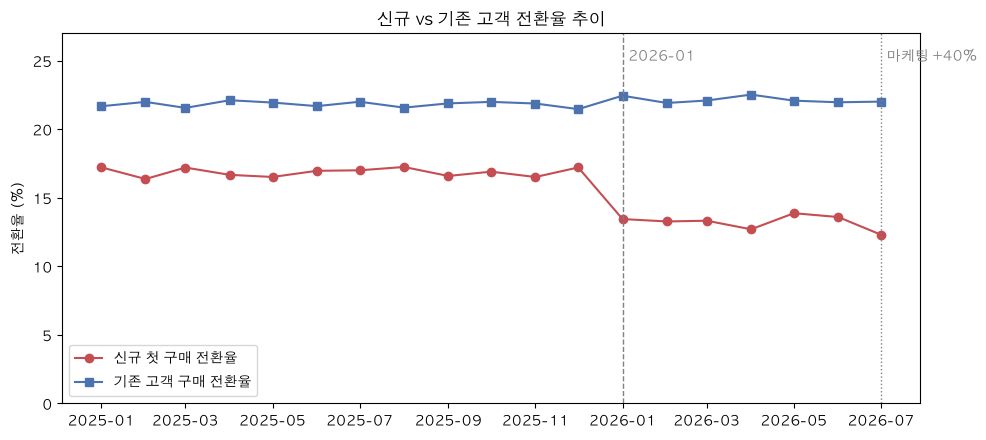

,신규 전환율(%),기존 전환율(%)
기간,,
2025년,16.86,21.81
2026년 1~6월,13.37,22.17
2026년 7월,12.30,22.01


In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
conv_new = kpi["new_buyers"] / kpi["new_visitors"]                   # 신규 첫 구매 전환율
ax.plot(kpi["month"], conv_new * 100, "o-", color="#C44E52", label="신규 첫 구매 전환율")
ax.plot(kpi["month"], kpi["existing_purchase_rate"] * 100, "s-", color="#4C72B0", label="기존 고객 구매 전환율")
ax.axvline(pd.Timestamp("2026-01-01"), color="gray", ls="--", lw=1)
ax.text(pd.Timestamp("2026-01-05"), 25, "2026-01", color="gray")
ax.axvline(pd.Timestamp("2026-07-01"), color="gray", ls=":", lw=1)
ax.text(pd.Timestamp("2026-07-05"), 25, "마케팅 +40%", color="gray")
ax.set_ylim(0, 27)
ax.set_ylabel("전환율 (%)")
ax.set_title("신규 vs 기존 고객 전환율 추이")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

# 기간별 평균 전환율
period = np.select([kpi["month"] < "2026-01-01", kpi["month"] < "2026-07-01"], ["2025년", "2026년 1~6월"], "2026년 7월")
summary = pd.DataFrame({"기간": period, "신규 전환율(%)": conv_new * 100,
                        "기존 전환율(%)": kpi["existing_purchase_rate"] * 100}).groupby("기간").mean()
summary

**해석**
- 신규 첫 구매 전환율은 2025년 내내 약 17%로 안정적 → **2026년 1월에 약 13%로 계단식 하락** → 이후 회복 없음
- 7월(12.3%)은 조금 더 낮지만, 하락의 대부분은 마케팅 확대 **이전인 1월**에 이미 일어남 → 7월 마케팅이 주원인은 아님
- 같은 기간 기존 고객 전환율은 약 22%로 변화 없음 → **신규 고객에게만 영향을 준 변화**
- 도메인 설정서와 대조: **2026-01-01 무료배송 기준 2만 원 → 3만 원 상향** 시점과 일치

**주의**
- 시점이 겹친다는 것만으로 원인이라고 단정할 수 없음 (같은 시기 다른 변화가 있었을 수 있음)
- 월별 집계로는 개별 고객의 행동을 볼 수 없음 → 이벤트 로그로 검증 필요

## 4. 가설 정리

| 가설 | 근거 (월별 KPI) | 이벤트 로그로 확인할 것 |
|---|---|---|
| H1. 1월 무료배송 기준 상향(2만 → 3만 원)이 신규 고객의 첫 구매를 막고 있다 | 1월 계단식 하락, 신규에게만 발생 | 신규 고객의 장바구니 금액이 3만 원에 못 미치는 비율, 기준 미달 장바구니의 전환율 |
| H2. 장바구니 금액이 작은 신규 고객이 이탈하고 있다 | 전환율 하락 + 첫 주문 금액 상승 | 장바구니 금액(또는 부족 금액) 구간별 전환율, 이탈 직전 행동 |
| H3. 7월 마케팅 유입 고객은 구매 의지가 낮다 | 7월 전환율이 1~6월보다 조금 더 낮음 | 유입 경로(광고 vs 기타)별 전환율 (영향은 작을 것으로 예상) |

- 가설을 확인하려면 먼저 이벤트 로그가 믿을 만한 상태인지 점검해야 함 → 다음 단계: 데이터 품질 점검

## 검산 메모

- 2장 로그 분해 중 세 요소의 합이 신규 매출 변화와 맞지 않는 것을 발견 (7월: 요소 합 0.022 vs 매출 0.035)
- 원인: 원본 KPI 테이블의 `revenue_new`가 `new_buyers × new_avg_first_order_amount`와 일치하지 않음 (매출 산식에 다른 평균 금액이 쓰임)
- 조치: 데이터 생성 노트북의 산식 오류를 수정하고 `raw.kpi_monthly`를 다시 적재 → 현재는 합이 정확히 일치 (위 `assert`로 확인)
- 교훈: 곱셈 관계로 분해한 지표는 분해한 요소를 다시 곱해 원래 값이 나오는지 검산할 것